# 01. EDA — 칼바람 패치 효과 분석 준비

16.21(패치 전) → 16.22(패치 후) 칼바람(큐 450) 데이터로 다음을 확인한다.

1. 수집 현황과 표본 편향
2. 챔피언별 승률 (항상 표본 수 n과 95% 신뢰구간 함께)
3. 지배자의 피갑옷 구매율 → 아이템 노출군 정의
4. 처치군·대조군 정의
5. 이중차분(DiD) 간이 추정

> 수집이 진행 중이면 숫자가 계속 바뀐다. 수집이 끝난 뒤 다시 실행하면 그대로 최종 결과가 된다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from db import get_engine

PRE, POST = "16.21", "16.22"
BLOODMAIL = 2501                      # 지배자의 피갑옷 (Data Dragon item ID)
ITEM_EXPOSED_MIN_RATE = 0.20          # 구매율 20% 이상이면 아이템 노출군
ITEM_EXPOSED_MIN_N = 30
DID_MIN_N = 30                        # DiD: 전후 각각 최소 경기 수

# 색: 상향 파랑 / 하향 주황 / 대조·기타 회색 (색약 구분 가능한 조합)
COL = {"buff": "#2a78d6", "nerf": "#eb6834", "other": "#8a8985"}
plt.rcParams.update({
    "font.family": "Apple SD Gothic Neo", "axes.unicode_minus": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8985", "axes.axisbelow": True, "figure.dpi": 110,
})
pd.set_option("display.max_rows", 60)

engine = get_engine()

## 1. 데이터 불러오기

In [2]:
matches = pd.read_sql("SELECT * FROM matches WHERE queue_id = 450", engine)
parts = pd.read_sql(
    """SELECT p.*, m.patch, m.early_surrender
       FROM participants p JOIN matches m USING (match_id)
       WHERE m.queue_id = 450""", engine)
changes = pd.read_csv(ROOT / "data/patch_changes/champion_changes.csv", dtype={"patch": str})

item_cols = [f"item{i}" for i in range(7)]
parts["bloodmail"] = parts[item_cols].eq(BLOODMAIL).any(axis=1)
print(f"matches {len(matches):,}  participants {len(parts):,}")

matches 40,584  participants 405,840


## 2. 수집 현황

In [3]:
summary = (matches.groupby("patch")
           .agg(n_matches=("match_id", "size"),
                remakes=("early_surrender", "sum"),
                first_game=("game_start", "min"),
                last_game=("game_start", "max"),
                median_min=("duration_s", lambda s: round(s.median() / 60, 1))))
summary["remake_%"] = (summary.remakes / summary.n_matches * 100).round(1)
summary

,n_matches,remakes,first_game,last_game,median_min,remake_%
patch,,,,,,
16.20,15,1,2026-10-20 15:37:38,2026-10-20 21:01:24,16.4,6.7
16.21,20001,640,2026-10-21 04:13:03,2026-11-03 21:02:21,17.9,3.2
16.22,20568,700,2026-11-03 22:33:09,2026-11-17 06:10:11,18.1,3.4


리메이크(`early_surrender = 1`)는 3분 무렵 무효 처리된 경기라 승률 분석에서 뺀다.
패치 구분은 날짜가 아니라 `gameVersion` 기준이다.

In [4]:
games = parts[parts.early_surrender == 0].copy()
avail = sorted(games.patch.unique())
print("분석 가능한 패치:", avail)

분석 가능한 패치: ['16.20', '16.21', '16.22']


## 3. 표본 편향 — 한 사람이 몇 경기에 나오나

스노볼 수집은 칼바람을 자주 하는 사람이 여러 번 잡히기 쉽다.
한 플레이어가 차지하는 비중이 크면 그 사람의 숙련도·챔피언 선호가 결과를 흔든다.

In [5]:
per_player = games.groupby(["patch", "puuid"]).size().rename("games").reset_index()
dist = (per_player.groupby("patch").games
        .describe(percentiles=[.5, .9, .99])[["count", "mean", "50%", "90%", "99%", "max"]]
        .rename(columns={"count": "players"}))
dist["players"] = dist.players.astype(int)
dist.round(2)

,players,mean,50%,90%,99%,max
patch,,,,,,
16.20,113,1.24,1.0,2.0,3.0,4.0
16.21,57218,3.38,2.0,7.0,16.0,49.0
16.22,59064,3.36,2.0,7.0,16.0,58.0


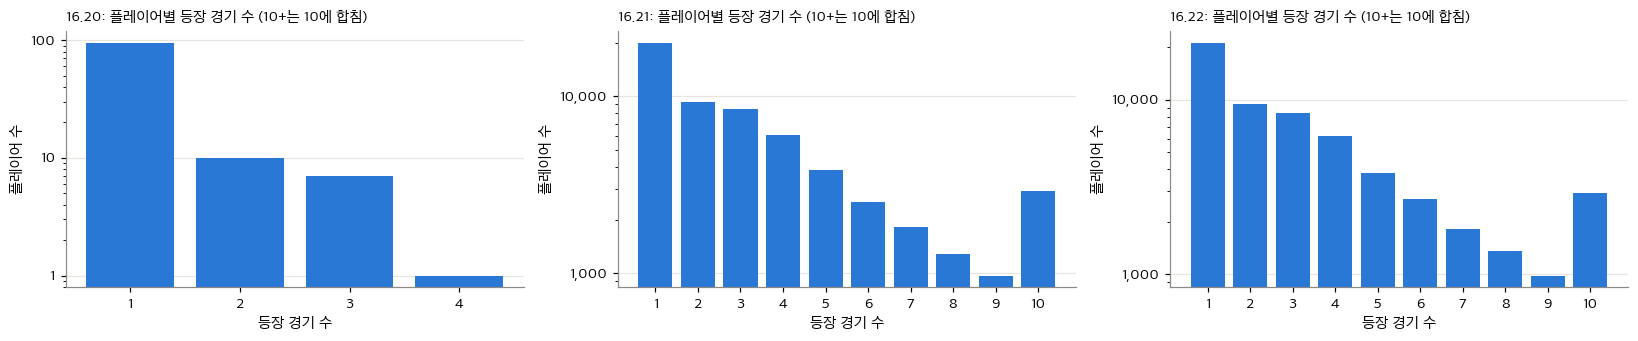

In [6]:
fig, axes = plt.subplots(1, len(avail), figsize=(5 * len(avail), 3.2), squeeze=False)
for ax, pt in zip(axes[0], avail):
    s = per_player[per_player.patch == pt].games.clip(upper=10).value_counts().sort_index()
    ax.bar(s.index, s.values, color=COL["buff"], width=0.8)
    ax.set_title(f"{pt}: 플레이어별 등장 경기 수 (10+는 10에 합침)", fontsize=10, loc="left")
    ax.set_xlabel("등장 경기 수"); ax.set_ylabel("플레이어 수")
    ax.set_yscale("log"); ax.grid(axis="x", visible=False)
    ax.set_xticks(s.index)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.tight_layout(); plt.show()

## 4. 챔피언별 승률 (n, 95% Wilson 신뢰구간)

칼바람은 같은 경기에 같은 챔피언이 두 번 나오지 않으므로, 챔피언별 승률은 경기 단위 독립 표본으로 근사한다.

In [7]:
def win_table(df):
    t = df.groupby(["patch", "champion_name"]).win.agg(n="size", wins="sum").reset_index()
    lo, hi = proportion_confint(t.wins, t.n, alpha=0.05, method="wilson")
    t["win_rate"], t["ci_low"], t["ci_high"] = t.wins / t.n, lo, hi
    return t

wr = win_table(games)
for pt in avail:
    w = wr[wr.patch == pt]
    print(f"{pt}: 챔피언 {len(w)}종, n>=100: {(w.n >= 100).sum()}종, n>=300: {(w.n >= 300).sum()}종, "
          f"중앙값 n={int(w.n.median())}")

16.20: 챔피언 89종, n>=100: 0종, n>=300: 0종, 중앙값 n=1
16.21: 챔피언 173종, n>=100: 173종, n>=300: 166종, 중앙값 n=1012
16.22: 챔피언 173종, n>=100: 173종, n>=300: 164종, 중앙값 n=1046


In [8]:
(wr[wr.patch == avail[-1]]
   .sort_values("n", ascending=False)
   .assign(win_rate=lambda d: (d.win_rate * 100).round(1),
           ci=lambda d: "[" + (d.ci_low * 100).round(1).astype(str) + ", "
                            + (d.ci_high * 100).round(1).astype(str) + "]")
   [["champion_name", "n", "win_rate", "ci"]]
   .head(20))

,champion_name,n,win_rate,ci
294,Ezreal,2791,50.0,"[48.2, 51.9]"
346,MissFortune,2782,52.8,"[50.9, 54.7]"
349,Morgana,2685,53.0,"[51.1, 54.8]"
315,Jhin,2660,50.4,"[48.5, 52.3]"
272,Ashe,2642,50.9,"[49.0, 52.8]"
318,Kaisa,2627,48.4,"[46.5, 50.3]"
282,Caitlyn,2586,51.4,"[49.5, 53.3]"
316,Jinx,2535,51.0,"[49.0, 52.9]"
339,Lux,2510,54.3,"[52.3, 56.2]"
420,Xerath,2493,49.7,"[47.7, 51.6]"


## 5. 지배자의 피갑옷 구매율 → 아이템 노출군

16.22에서 지배자의 피갑옷(공격력 30→40, 응징 +0~12% → +0~10%)이 바뀌었다.
이 아이템을 자주 사는 챔피언은 본인이 안 바뀌어도 간접 영향을 받으므로 대조군에서 뺀다.
기준은 **패치 전(16.21)** 구매율이다. 16.21 데이터가 없으면 임시로 16.22를 쓴다.

In [9]:
base_patch = PRE if PRE in avail else avail[-1]
bm = (games[games.patch == base_patch].groupby("champion_name")
      .agg(n=("bloodmail", "size"), buyers=("bloodmail", "sum")))
bm["buy_rate"] = bm.buyers / bm.n
item_exposed = sorted(bm[(bm.buy_rate >= ITEM_EXPOSED_MIN_RATE) & (bm.n >= ITEM_EXPOSED_MIN_N)].index)
print(f"기준 패치 {base_patch} / 노출군 (구매율 >= {ITEM_EXPOSED_MIN_RATE:.0%}, n >= {ITEM_EXPOSED_MIN_N}):",
      item_exposed or "아직 없음 (표본 부족)")
bm[bm.buyers > 0].sort_values("buy_rate", ascending=False).head(15).round(3)

기준 패치 16.21 / 노출군 (구매율 >= 20%, n >= 30): ['Kled', 'Sett']


,n,buyers,buy_rate
champion_name,,,
Sett,968,578,0.597
Kled,132,35,0.265
Sion,530,31,0.058
Urgot,584,34,0.058
Illaoi,517,15,0.029
Yorick,266,4,0.015
Garen,1072,16,0.015
DrMundo,889,13,0.015
Tryndamere,637,9,0.014


## 6. 처치군·대조군 정의

`data/patch_changes/champion_changes.csv`(16.22, 직접 확인한 목록) 기준.

| 그룹 | 챔피언 |
|---|---|
| buff | 직접 상향 (쉔 제외) |
| nerf | 직접 하향 |
| placebo | 쉔 — 몬스터 대상 피해만 변경 → 칼바람 효과가 0이어야 정상 |
| rework | 멜 — 방향 단정 불가 |
| item | 지배자의 피갑옷 노출군 (세트 등) |
| control | 나머지 전부 (헤카림·클래식 섹션 포함) |

In [10]:
rift = changes[(changes.patch == POST) & (changes.applies_to_aram == "yes")]
group = {}
for _, r in rift.iterrows():
    if r.champion_name == "Shen":
        group[r.champion_name] = "placebo"
    elif r.direction == "rework":
        group[r.champion_name] = "rework"
    else:
        group[r.champion_name] = r.direction          # buff / nerf
for c in item_exposed:
    group.setdefault(c, "item")
group.setdefault("Sett", "item")   # 패치노트가 직접 언급한 피갑옷 핵심 사용자

games["group"] = games.champion_name.map(group).fillna("control")
games.groupby(["group", "patch"]).champion_name.nunique().unstack(fill_value=0)

patch,16.20,16.21,16.22
group,,,
buff,4,9,9
control,82,157,157
item,0,2,2
nerf,1,3,3
placebo,1,1,1
rework,1,1,1


## 7. 이중차분(DiD) 간이 추정

챔피언 c마다 c와 대조군만 남겨 선형확률모형을 적합한다.

`win ~ is_c + post + is_c:post`  →  `is_c:post` 계수가 DiD 추정치
(= c의 승률 변화 − 대조군의 승률 변화)

- 같은 경기의 참가자는 승패가 묶여 있으므로 표준오차는 **경기 단위 군집(cluster) 보정**을 한다.
- 소표본 보정(베이지안 축소), 팀 조합 통제, 플레이어 가중치는 다음 단계에서 추가한다.

In [11]:
def did(df, champ):
    d = df[(df.champion_name == champ) | (df.group == "control")].copy()
    d["is_c"] = (d.champion_name == champ).astype(int)
    d["post"] = (d.patch == POST).astype(int)
    m = smf.ols("win ~ is_c + post + is_c:post", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d.match_id)[0]})
    est, (lo, hi) = m.params["is_c:post"], m.conf_int().loc["is_c:post"]
    n_pre = int(((d.is_c == 1) & (d.post == 0)).sum())
    n_post = int(((d.is_c == 1) & (d.post == 1)).sum())
    return dict(champion=champ, group=group.get(champ, "control"), n_pre=n_pre, n_post=n_post,
                did=est, ci_low=lo, ci_high=hi, p=m.pvalues["is_c:post"])

ready = {PRE, POST} <= set(avail)
if not ready:
    print(f"{PRE} 데이터가 아직 없어 DiD를 건너뛴다. 현재 패치: {avail}")
else:
    dd = games[games.patch.isin([PRE, POST])]
    targets = [c for c, g in group.items() if g in ("buff", "nerf", "placebo", "rework", "item")]
    res_all = pd.DataFrame([did(dd, c) for c in targets if (dd.champion_name == c).any()])
    enough = (res_all.n_pre >= DID_MIN_N) & (res_all.n_post >= DID_MIN_N)
    res = res_all[enough].sort_values("did")
    short = res_all[~enough]
    if len(short):
        print(f"표본 부족 (전후 각 {DID_MIN_N}경기 미만, 추정에서 제외):",
              ", ".join(f"{c}({a}→{b})" for c, a, b in zip(short.champion, short.n_pre, short.n_post)))
    display(res.assign(**{k: (res[k] * 100).round(1) for k in ["did", "ci_low", "ci_high"]})
               .round({"p": 3}))

,champion,group,n_pre,n_post,did,ci_low,ci_high,p
3,Locke,nerf,661,667,-3.2,-8.6,2.1,0.237
15,Sett,item,968,1007,-2.3,-6.7,2.1,0.305
0,AurelionSol,buff,1012,1146,-1.4,-5.6,2.9,0.530
5,Mel,rework,2094,1564,-1.3,-4.6,2.0,0.442
4,Maokai,buff,1329,1549,-0.8,-4.5,2.9,0.668
13,Zaahen,buff,432,386,-0.3,-7.2,6.6,0.932
8,Shen,placebo,849,999,-0.2,-4.8,4.3,0.916
2,Kayle,buff,1023,1013,0.3,-4.0,4.7,0.886
12,Yasuo,nerf,1166,1254,0.5,-3.5,4.5,0.812
10,Thresh,nerf,1724,1576,0.5,-2.9,4.0,0.768


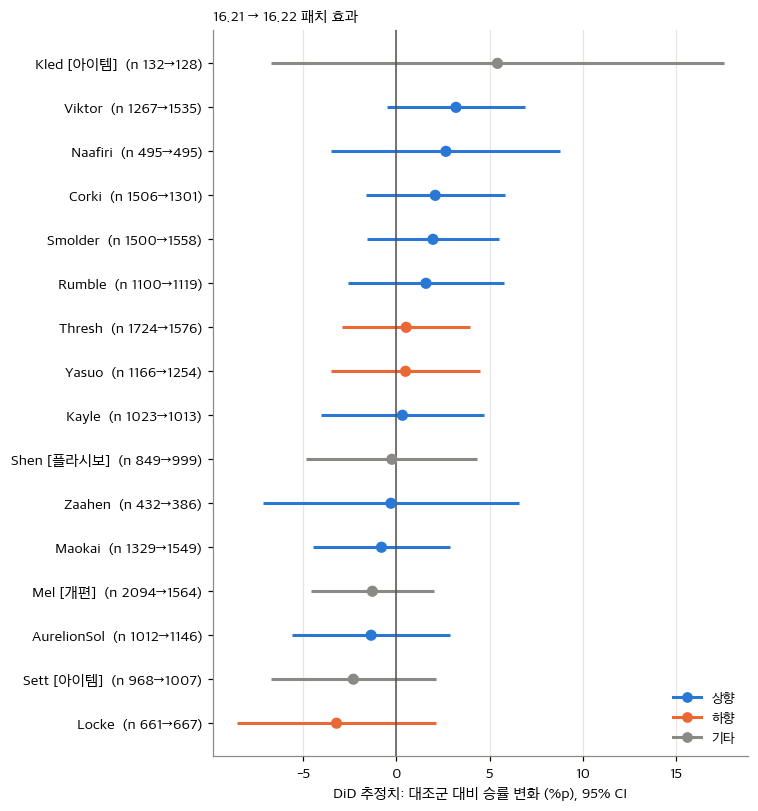

In [12]:
TAG = {"placebo": " [플라시보]", "rework": " [개편]", "item": " [아이템]"}
if ready and len(res):
    fig, ax = plt.subplots(figsize=(7, 0.38 * len(res) + 1.4))
    y = np.arange(len(res))
    colors = [COL.get(g, COL["other"]) for g in res.group]
    ax.hlines(y, res.ci_low * 100, res.ci_high * 100, color=colors, linewidth=2)
    ax.scatter(res.did * 100, y, color=colors, s=40, zorder=3)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.set_yticks(y, [f"{c}{TAG.get(g, '')}  (n {a}→{b})"
                      for c, g, a, b in zip(res.champion, res.group, res.n_pre, res.n_post)])
    ax.set_xlabel("DiD 추정치: 대조군 대비 승률 변화 (%p), 95% CI")
    ax.set_title(f"{PRE} → {POST} 패치 효과", fontsize=10, loc="left")
    handles = [plt.Line2D([], [], color=COL[k], marker="o", linewidth=2, label=l)
               for k, l in [("buff", "상향"), ("nerf", "하향"), ("other", "기타")]]
    ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=9)
    ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()
elif ready:
    print("표본이 충분한 챔피언이 아직 없다.")

## 8. 다음 단계

- 수집 완료 후 전체 재실행 → 표본 수·신뢰구간 확인
- 쉔(placebo) 추정치가 0 근처인지 확인 → 방법 점검
- 베이지안 축소(경험적 베이즈)로 소표본 챔피언 보정
- 플레이어별 가중치 상한 (헤비 유저 영향 제한)
- 팀 조합 등 교란 변수 통제